In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

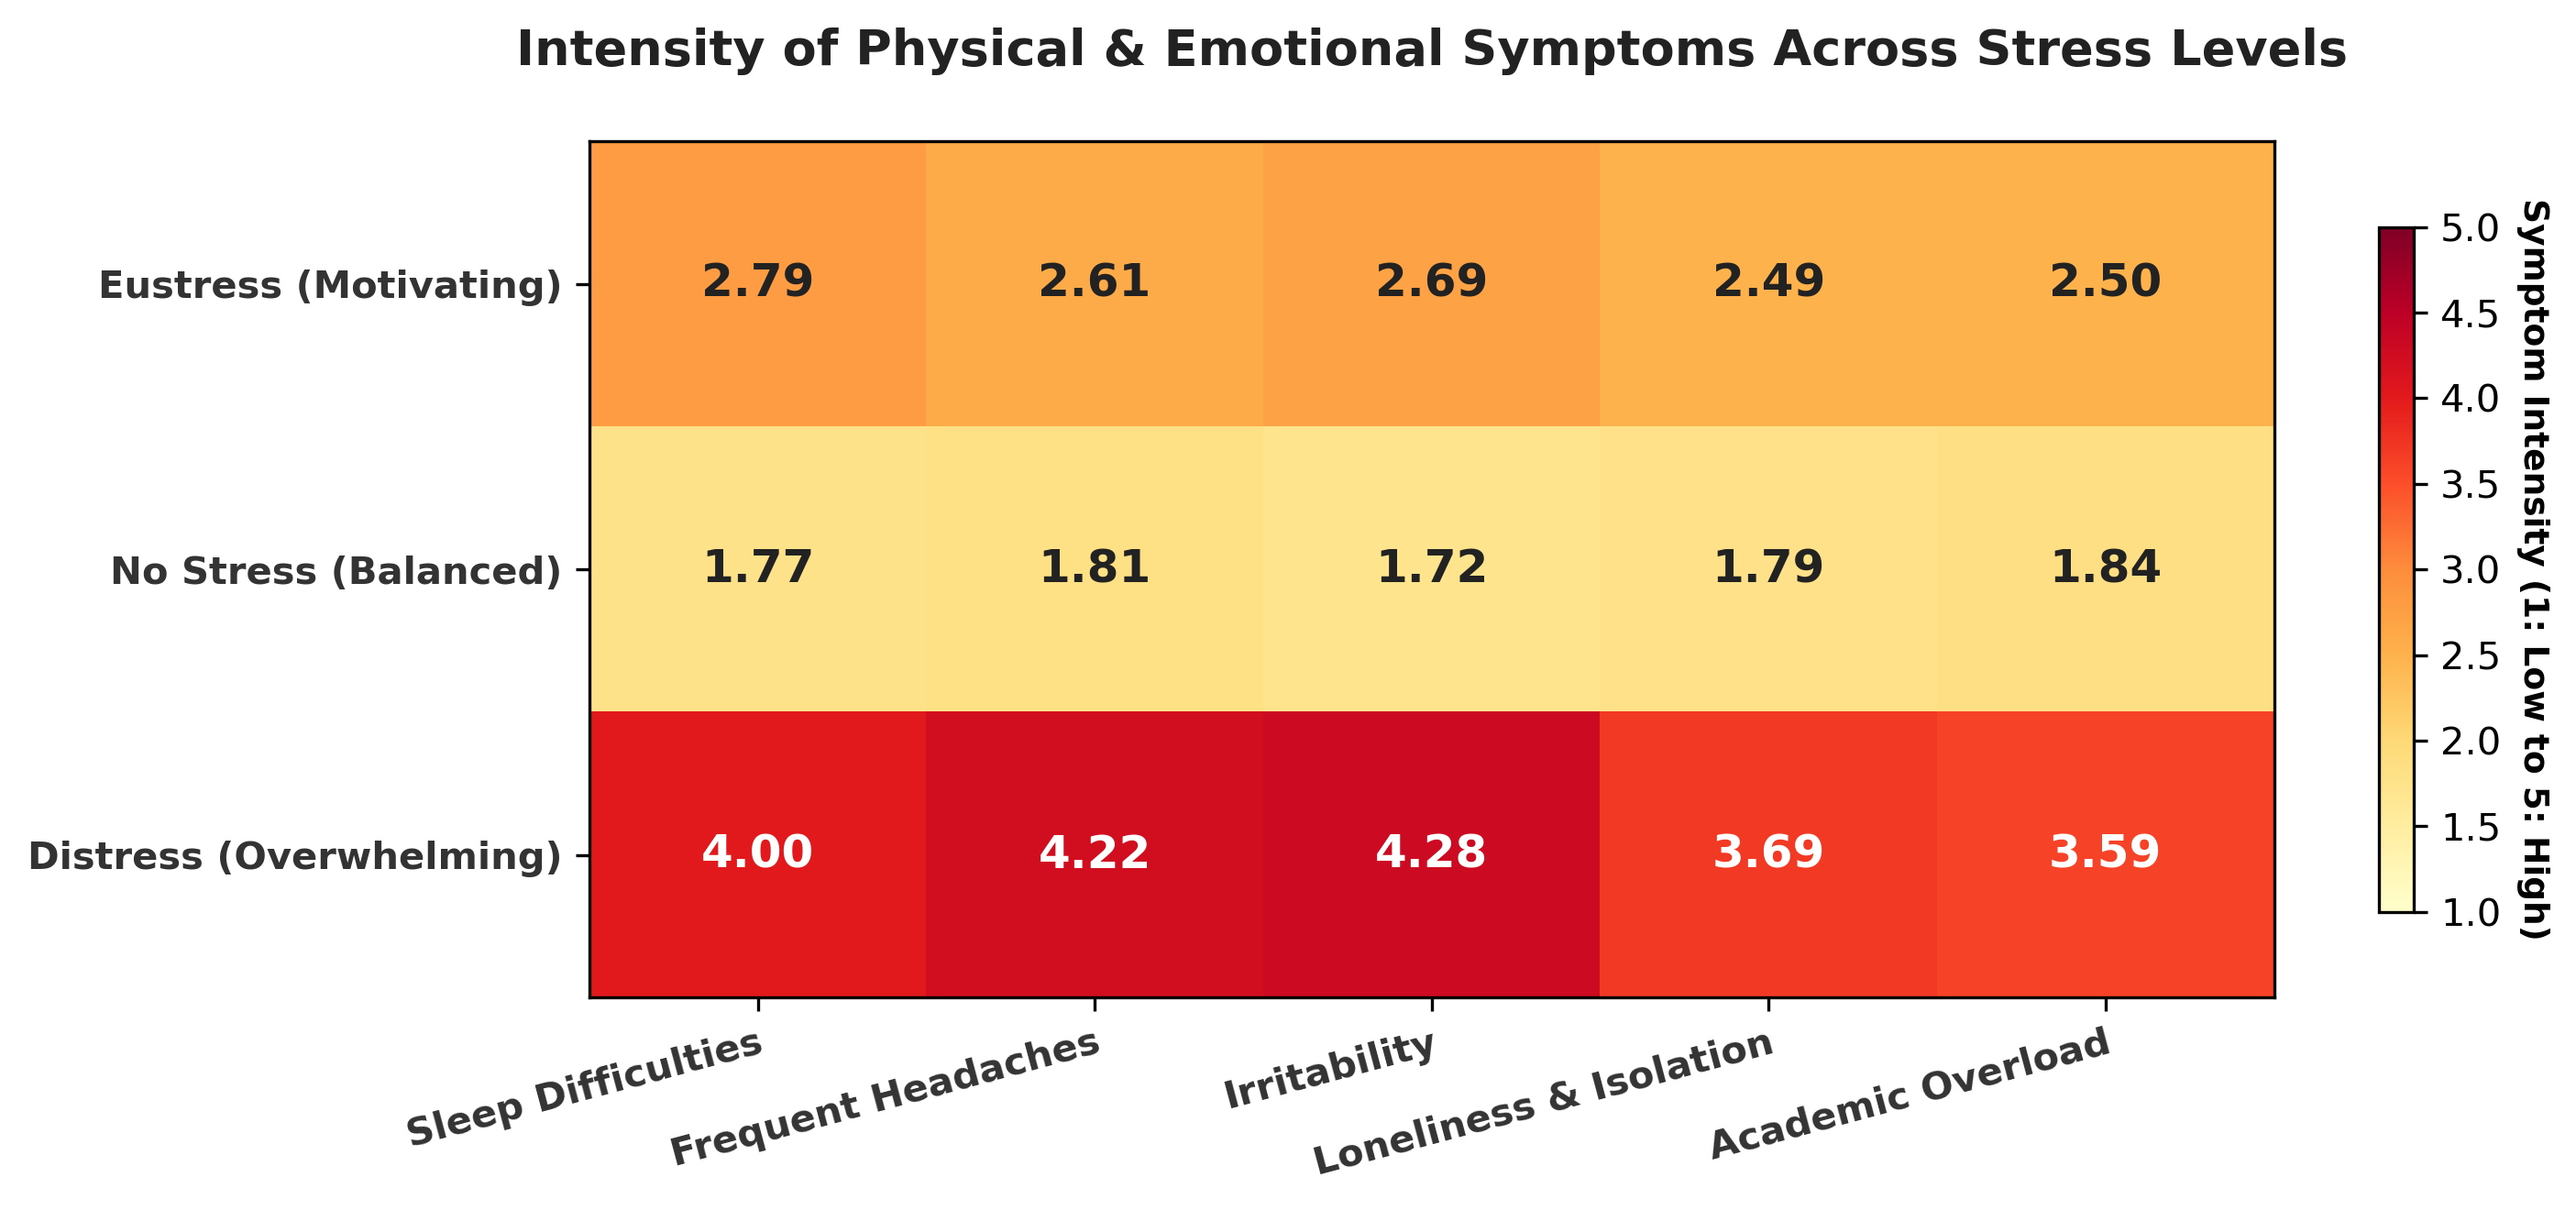

In [10]:
df = pd.read_csv('Stress_Dataset.csv')

sleep_col = 'Do you face any sleep problems or difficulties falling asleep?'
stress_col = 'Which type of stress do you primarily experience?'

df['Stress_Short'] = df[stress_col].map({
    'Eustress (Positive Stress) - Stress that motivates and enhances performance.': 'Eustress (Motivating)',
    'No Stress - Currently experiencing minimal to no stress.': 'No Stress (Balanced)',
    'Distress (Negative Stress) - Stress that causes anxiety and impairs well-being.': 'Distress (Overwhelming)'
})

factors = [
    'Do you face any sleep problems or difficulties falling asleep?',
    'Have you been getting headaches more often than usual?',
    'Do you get irritated easily?',
    'Do you often feel lonely or isolated?',
    'Do you feel overwhelmed with your academic workload?'
]

factor_labels = [
    'Sleep Difficulties',
    'Frequent Headaches',
    'Irritability',
    'Loneliness & Isolation',
    'Academic Overload'
]

heatmap_data = df.groupby('Stress_Short')[factors].mean()
heatmap_data.columns = factor_labels

heatmap_data = heatmap_data.reindex(['Eustress (Motivating)', 'No Stress (Balanced)', 'Distress (Overwhelming)'])

fig, ax = plt.subplots(figsize=(10, 4.5), dpi=300)

im = ax.imshow(heatmap_data.values, cmap='YlOrRd', aspect='auto', vmin=1, vmax=5)

ax.set_xticks(np.arange(len(factor_labels)))
ax.set_yticks(np.arange(len(heatmap_data.index)))
ax.set_xticklabels(factor_labels, fontsize=10, fontweight='bold', color='#333333')
ax.set_yticklabels(heatmap_data.index, fontsize=10, fontweight='bold', color='#333333')

plt.setp(ax.get_xticklabels(), rotation=15, ha="right", rotation_mode="anchor")

for i in range(len(heatmap_data.index)):
    for j in range(len(factor_labels)):
        val = heatmap_data.values[i, j]
        text_color = "white" if val > 3.2 else "#222222"
        text = ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=text_color, fontweight='bold', fontsize=12)

cbar = ax.figure.colorbar(im, ax=ax, shrink=0.8)
cbar.ax.set_ylabel("Symptom Intensity (1: Low to 5: High)", rotation=-90, va="bottom", fontsize=9, fontweight='bold')

ax.set_title("Intensity of Physical & Emotional Symptoms Across Stress Levels", fontsize=13, fontweight='bold', pad=20, color='#222222')
ax.grid(False)

plt.tight_layout()
plt.show()